In [21]:
# --- Model 1: Feed-Forward Neural Network on flattened spectrograms ---
# Inputs ready from Section 3.5:
#   Xf_train (6393, 16384) | Xf_val | Xf_test   flattened pixels
#   y_train / y_val / y_test                    integer genre_id
#
# TBD

# TODO: plot train vs val loss/accuracy

# When fitted, score it through the shared table:
# record("Feed-Forward NN", KerasModel, Xf_train, Xf_val, "2 hidden layers")
# plot_confusion(y_val, _labels(model, Xc_val), "<model name> - validation")

## Model 1: Feed-Forward Neural Network on Flattened Spectrogram

In [1]:
# load modules needed

import numpy as np
import numpy as np
from matplotlib import pyplot as plt
import pandas as pd

import tensorflow as tf
from tensorflow import keras
from keras import metrics
tf.get_logger().setLevel('INFO')
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

---
### Step 1: Data Ingesetion
#### Use flattened normalized data from Step 3.5

Prior to this step, data has been split into training, validation, and test sets, and has been pre-processed to be ready for model training


In [2]:
# load in from local data
d = np.load("../data/local/splits.npz", allow_pickle=True)

Xf_train, Xf_val, Xf_test = d["Xf_train"], d["Xf_val"], d["Xf_test"]
y_train, y_val, y_test = d["y_train"], d["y_val"], d["y_test"]


In [3]:
# Resize it to 128 x 128 and scale by the average per mel band of the training set

def to3d(X): 
    return X.reshape(len(X), 128, 128)

tr = to3d(Xf_train)
mu = tr.mean(axis=(0, 2), keepdims=True)         # one mean per mel band
sd = tr.std(axis=(0, 2), keepdims=True) + 1e-6

def std_flat(X): 
    return ((to3d(X) - mu) / sd).reshape(len(X), -1)

Xs_train, Xs_val, Xs_test = std_flat(Xf_train), std_flat(Xf_val), std_flat(Xf_test)

---
### Step 2: Build Model
#### Builds a feed-forward neural network that can have vary in many ways allowing for experimental testing

In [35]:
def build_model(n_classes,num_features,
                hidden_layer_sizes=[],
                activation='relu',
                optimizer='Adam',
                learning_rate=1e-4,
                metric='metric',
                dropout=0.5
                ):
    """
    Args:
    n_classes: Number of output classes in the dataset.
    n_features: Number of features in the input dataset.
    hidden_layer_sizes: A list with the number of units in each hidden layer.
    activation: The activation function to use for the hidden layers.
    optimizer: The optimizer to use (SGD, Adam).
    learning_rate: The desired learning rate for the optimizer.
    metric: The desired metric.
    dropout: dropout rate applied after each hidden layer

    Returns:
    model: A tf.keras model (graph).
    """
    tf.keras.backend.clear_session()
    np.random.seed(0)
    tf.random.set_seed(0)

    # YOUR CODE HERE

    if optimizer == 'SGD':
        opt = tf.keras.optimizers.SGD(learning_rate=learning_rate)
    elif optimizer == 'Adam':
        opt = tf.keras.optimizers.Adam(learning_rate=learning_rate)

    model = tf.keras.Sequential()



    # initial layer
    model.add(tf.keras.Input(shape=(num_features,), name='Input'))


    # loop through the hidden layers
    for l in range(len(hidden_layer_sizes)):
        layer_output = f'Output{l}'
        model.add(tf.keras.layers.Dense(units=hidden_layer_sizes[l], activation=activation, name=layer_output))
        model.add(tf.keras.layers.Dropout(dropout))



        # create output layer
    model.add(tf.keras.layers.Dense(
            units=n_classes,  
            use_bias=True,
            activation=None, 
            name='Output'
            ))


    model.compile(
        optimizer = opt,
        loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),  
        metrics = [metric]
    )

    return model

---
### Step 3: Experiment with Hyperparameters
#### Build function to train the model on input hyperparameters, and output the accuracy of the train and validation data sets

In [5]:
# Build the model.
model = build_model(
    n_classes=len(np.unique(y_train)),num_features = Xs_train.shape[1],
    hidden_layer_sizes=[128,64],
    activation='relu',
    optimizer='Adam',
    metric='accuracy',
    learning_rate=1e-4)

In [6]:
   
# Find the best epoch available. Stop if it starts going down with a patience of 8
early = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=8, restore_best_weights=True)

history = model.fit(Xs_train, y_train, epochs=100, batch_size=32,
                    validation_data=(Xs_val, y_val),
                    callbacks=[early], verbose=0)

best = int(np.argmin(history.history['val_loss']))
train_accuracy = history.history['accuracy']
val_accuracy = history.history['val_accuracy']
print('Best epoch %d | train %.4f | val %.4f'
    % (best + 1, train_accuracy[best], val_accuracy[best]))

Best epoch 2 | train 0.2115 | val 0.3250


---
### Step 4: Train a second model that averages over the nearest 2x2 grid


In [7]:
# Pool average over 2x2
# --- 2x2 average pooling: (n, 16384) -> (n, 4096) ---
def pool2(X):
    # (n, 128 mel, 128 time) -> (n, 64, 2, 64, 2) -> average each 2x2 block
    X3 = X.reshape(len(X), 64, 2, 64, 2).mean(axis=(2, 4))   # (n, 64, 64)
    return X3.reshape(len(X), -1)                             # (n, 4096)

Xp_train, Xp_val, Xp_test = pool2(Xs_train), pool2(Xs_val), pool2(Xs_test)
print(Xp_train.shape, Xp_val.shape, Xp_test.shape)   # expect (6393, 4096) (800, 4096) (800, 4096)

(6393, 4096) (800, 4096) (800, 4096)


In [8]:
# --- Fresh model, same setup as before but on the pooled input ---
model_p = build_model(
    n_classes=len(np.unique(y_train)),
    num_features=Xp_train.shape[1],
    hidden_layer_sizes=[256, 128],
    activation='relu',
    optimizer='Adam',
    learning_rate=1e-4,
    metric='accuracy',
)

early = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=8, restore_best_weights=True)

history_p = model_p.fit(Xp_train, y_train, epochs=100, batch_size=32,
                        validation_data=(Xp_val, y_val),
                        callbacks=[early], verbose=0)

best = int(np.argmin(history_p.history['val_loss']))
print('Best epoch %d of %d | val acc %.4f'
      % (best + 1, len(history_p.history['val_loss']),
         history_p.history['val_accuracy'][best]))

# Fair comparison: both evaluated with dropout off
print("train:", model_p.evaluate(Xp_train, y_train, verbose=0)[1])
print("val:  ", model_p.evaluate(Xp_val,   y_val,   verbose=0)[1])


Best epoch 11 of 19 | val acc 0.3425
train: 0.4781792461872101
val:   0.3425000011920929


Did not really improve the validation significantly. It seems like this data is dramatically overfitting. Why not try something different?

---
### Step 5: Use Single Value Decomposition to Reduce Dimensionality

In [31]:
# X: (n_samples, 128*128), ideally log-magnitude (dB) spectrograms
scaler = StandardScaler().fit(Xf_train)

pca = PCA(n_components=50, svd_solver="randomized",random_state=0)  # or fixed e.g. 200
pca.fit(scaler.transform(Xf_train))

# use the scaler to transform the val set also
X_train_min = pca.transform(scaler.transform(Xf_train))
X_val_min   = pca.transform(scaler.transform(Xf_val))
# feed Z_train into your FFNN: input dim drops from 16384 to ~100-300

In [49]:
model_pca = build_model(
    n_classes=len(np.unique(y_train)),
    num_features=X_train_min.shape[1],
    hidden_layer_sizes=[128],
    activation='relu',
    optimizer='Adam',
    learning_rate=5e-4,
    metric='accuracy',
)
early = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=8, restore_best_weights=True)

history_pca = model_pca.fit(X_train_min, y_train, epochs=200, batch_size=32,
                        validation_data=(X_val_min, y_val),
                        callbacks=[early], verbose=0)

best = int(np.argmin(history_pca.history['val_loss']))
print('Best epoch %d of %d | val acc %.4f'
      % (best + 1, len(history_pca.history['val_loss']),
         history_pca.history['val_accuracy'][best]))

# Fair comparison: both evaluated with dropout off
print("train:", model_pca.evaluate(X_train_min, y_train, verbose=0)[1])
print("val:  ", model_pca.evaluate(X_val_min,   y_val,   verbose=0)[1])

Best epoch 34 of 42 | val acc 0.3975
train: 0.5219771862030029
val:   0.39750000834465027


In [48]:
from sklearn.linear_model import LogisticRegression

n_classes = len(np.unique(y_train))

# PCA on band-standardized data, fit once at max k
pca = PCA(n_components=400, svd_solver="randomized", random_state=0)
pca.fit(Xs_train)
Z_tr = pca.transform(Xs_train)
Z_va = pca.transform(Xs_val)

# unit-variance each component using train stats (same as whiten=True)
zs = Z_tr.std(axis=0) + 1e-8
Z_tr, Z_va = Z_tr / zs, Z_va / zs

results = []
dropout = 0.5
hidden_layer_sizes = [128]

for k in [50, 100, 200]:
    Ztr, Zva = Z_tr[:, :k], Z_va[:, :k]

    logreg = LogisticRegression(max_iter=3000, C=0.1).fit(Ztr, y_train)
    lr_val = logreg.score(Zva, y_val)

    m = build_model(n_classes, k, hidden_layer_sizes=hidden_layer_sizes,
                    learning_rate=1e-3, metric='accuracy', dropout=dropout)
    early = tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=8, restore_best_weights=True)
    m.fit(Ztr, y_train, epochs=200, batch_size=32,
          validation_data=(Zva, y_val), callbacks=[early], verbose=0)

    results.append((k,
                    m.evaluate(Ztr, y_train, verbose=0)[1],
                    m.evaluate(Zva, y_val, verbose=0)[1],
                    lr_val))
    print("k=%d | FFNN train %.3f val %.3f | logreg val %.3f" % results[-1])

pd.DataFrame(results, columns=["k", "ffnn_train", "ffnn_val", "logreg_val"])

k=50 | FFNN train 0.549 val 0.394 | logreg val 0.347
k=100 | FFNN train 0.540 val 0.360 | logreg val 0.345
k=200 | FFNN train 0.583 val 0.371 | logreg val 0.354


,k,ffnn_train,ffnn_val,logreg_val
0,50,0.548882,0.39375,0.34750
1,100,0.539966,0.36000,0.34500
2,200,0.583138,0.37125,0.35375


---
### Step 6: Plot Final Model Confusion Matrix

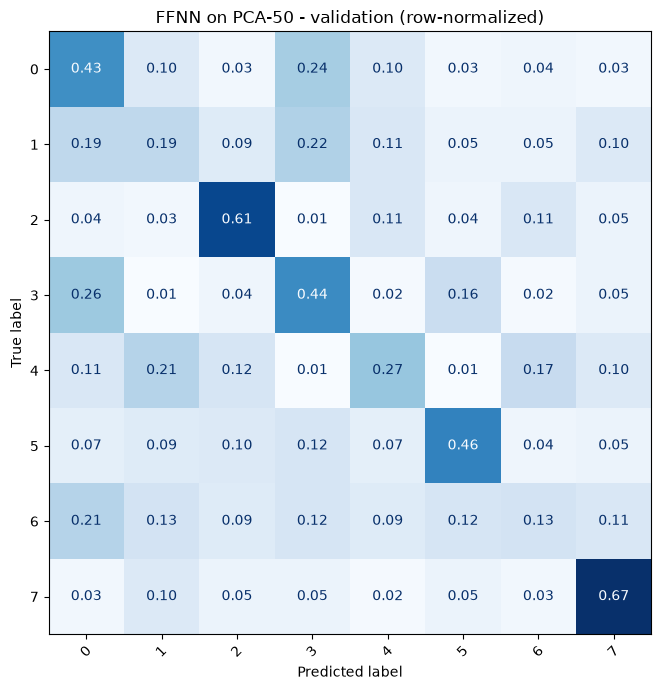

              precision    recall  f1-score   support

           0      0.321     0.430     0.368       100
           1      0.221     0.190     0.204       100
           2      0.540     0.610     0.573       100
           3      0.364     0.440     0.398       100
           4      0.342     0.270     0.302       100
           5      0.500     0.460     0.479       100
           6      0.220     0.130     0.164       100
           7      0.578     0.670     0.620       100

    accuracy                          0.400       800
   macro avg      0.386     0.400     0.388       800
weighted avg      0.386     0.400     0.388       800



In [53]:
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

k = 50
Ztr, Zva = Z_tr[:, :k], Z_va[:, :k]

m = build_model(n_classes, k, hidden_layer_sizes=[128],
                learning_rate=1e-3, metric='accuracy', dropout=0.5)
early = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=8, restore_best_weights=True)
m.fit(Ztr, y_train, epochs=200, batch_size=32,
      validation_data=(Zva, y_val), callbacks=[early], verbose=0)

# the model outputs logits, so argmax gives the predicted class
y_pred = m.predict(Zva, verbose=0).argmax(axis=1)

classes = np.unique(y_train)
# replace with genre names if you have a mapping, e.g. [id_to_name[c] for c in classes]
names = [str(c) for c in classes]

cm = confusion_matrix(y_val, y_pred, labels=classes, normalize="true")  # rows sum to 1
fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay(cm, display_labels=names).plot(
    ax=ax, cmap="Blues", values_format=".2f", xticks_rotation=45, colorbar=False)
ax.set_title(f"FFNN on PCA-{k} - validation (row-normalized)")
plt.tight_layout(); plt.show()

print(classification_report(y_val, y_pred, labels=classes, target_names=names, digits=3))